# Importing the Necessary Python Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import openpyxl
import re
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc, accuracy_score, classification_report, precision_recall_curve

# Importing the Main Dataset

In [2]:
main_data = pd.read_csv("emails.csv")

# Data Preprocessing

In [3]:
# List of columns to exclude from the sum calculation
exclude_columns = ['Email No.', 'Prediction']

# Calculating email_length
main_data['email_length'] = main_data.drop(columns=exclude_columns).sum(axis=1)

# Calculating the count of capitalized words for each row
main_data['capitalization_count'] = main_data[[col for col in main_data.columns if col.istitle() and col not in exclude_columns]].sum(axis=1)

# Calculating word_count (assuming each non-zero entry in a word column counts as one word)
main_data['word_count'] = main_data.drop(columns=exclude_columns).apply(lambda x: (x > 0).sum(), axis=1)

# Display the updated DataFrame
print(main_data)

       Email No.  the  to  ect  and  for  of    a  you  hou  ...  lay  \
0        Email 1    0   0    1    0    0   0    2    0    0  ...    0   
1        Email 2    8  13   24    6    6   2  102    1   27  ...    0   
2        Email 3    0   0    1    0    0   0    8    0    0  ...    0   
3        Email 4    0   5   22    0    5   1   51    2   10  ...    0   
4        Email 5    7   6   17    1    5   2   57    0    9  ...    0   
...          ...  ...  ..  ...  ...  ...  ..  ...  ...  ...  ...  ...   
5167  Email 5168    2   2    2    3    0   0   32    0    0  ...    0   
5168  Email 5169   35  27   11    2    6   5  151    4    3  ...    0   
5169  Email 5170    0   0    1    1    0   0   11    0    0  ...    0   
5170  Email 5171    2   7    1    0    2   1   28    2    0  ...    0   
5171  Email 5172   22  24    5    1    6   5  148    8    2  ...    0   

      infrastructure  military  allowing  ff  dry  Prediction  email_length  \
0                  0         0         0   0

In [4]:
main_data.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,lay,infrastructure,military,allowing,ff,dry,Prediction,email_length,capitalization_count,word_count
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,53,0.0,35
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,1,0,0,2203,0.0,277
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,113,0.0,46
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,1019,0.0,173
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,1,0,0,1075,0.0,168


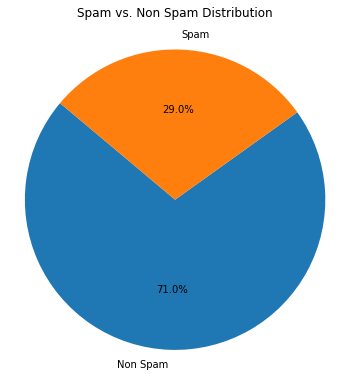

In [5]:
prediction_counts = main_data['Prediction'].value_counts()

# Creating a pie chart
plt.figure(figsize=(6, 6))
plt.pie(prediction_counts, labels=['Non Spam', 'Spam'], autopct='%1.1f%%', startangle=140)
plt.title('Spam vs. Non Spam Distribution', pad=20)
plt.axis('equal')

# Display the pie chart
plt.show()

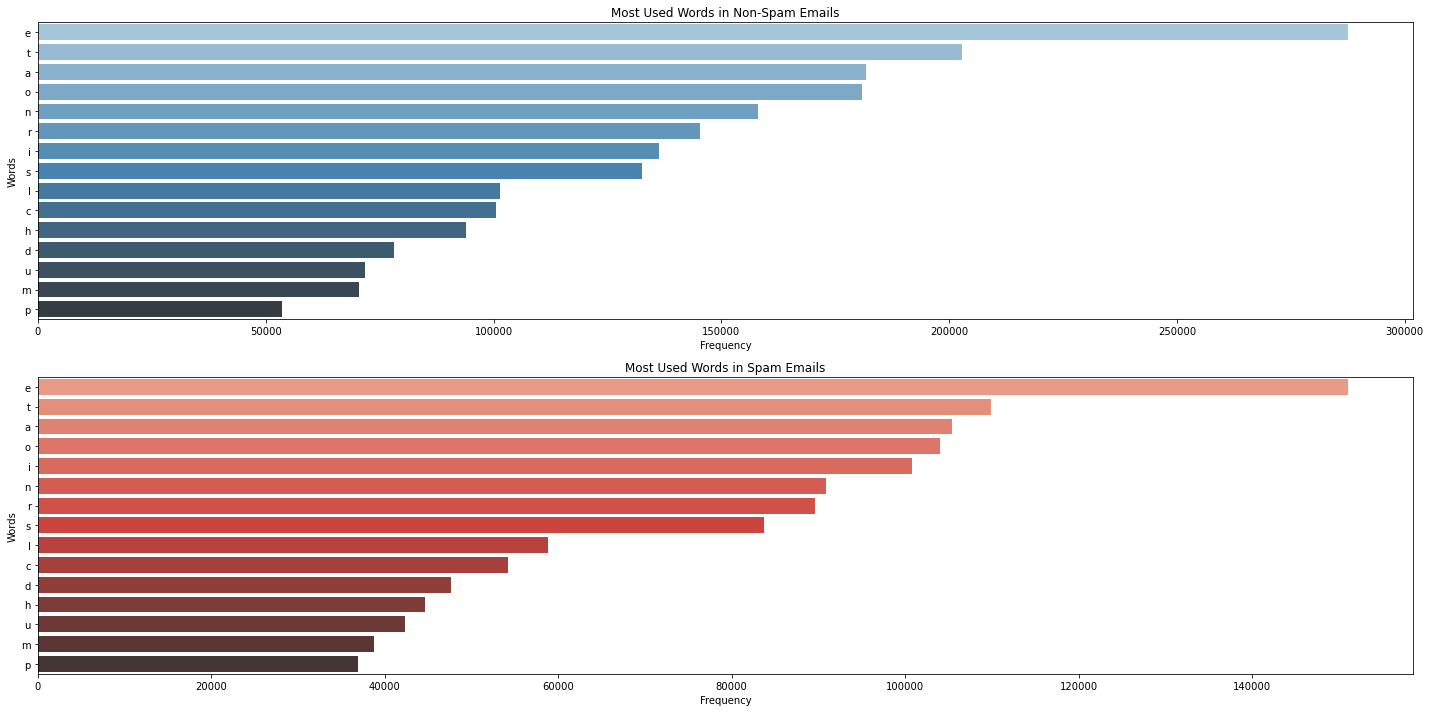

In [6]:
# Define columns to exclude from the sum (non-word columns)
exclude_columns = ['Email No.', 'Prediction', 'email_length', 'capitalization_count', 'word_count']

# Split the DataFrame based on the 'Prediction' value
df_non_spam = main_data[main_data['Prediction'] == 0]
df_spam = main_data[main_data['Prediction'] == 1]

# Calculate the sum of each word's occurrences for Non-Spam and Spam
word_sums_non_spam = df_non_spam.drop(columns=exclude_columns).sum().sort_values(ascending=False).head(15)
word_sums_spam = df_spam.drop(columns=exclude_columns).sum().sort_values(ascending=False).head(15)

# Setting up the plots
plt.figure(figsize=(20, 10))

# Plot for Non-Spam words
plt.subplot(2, 1, 1)
sns.barplot(x=word_sums_non_spam.values, y=word_sums_non_spam.index, palette="Blues_d")
plt.title("Most Used Words in Non-Spam Emails")
plt.xlabel("Frequency")
plt.ylabel("Words")

# Plot for Spam words
plt.subplot(2, 1, 2)
sns.barplot(x=word_sums_spam.values, y=word_sums_spam.index, palette="Reds_d")
plt.title("Most Used Words in Spam Emails")
plt.xlabel("Frequency")
plt.ylabel("Words")

# Show the plots
plt.tight_layout()
plt.show()

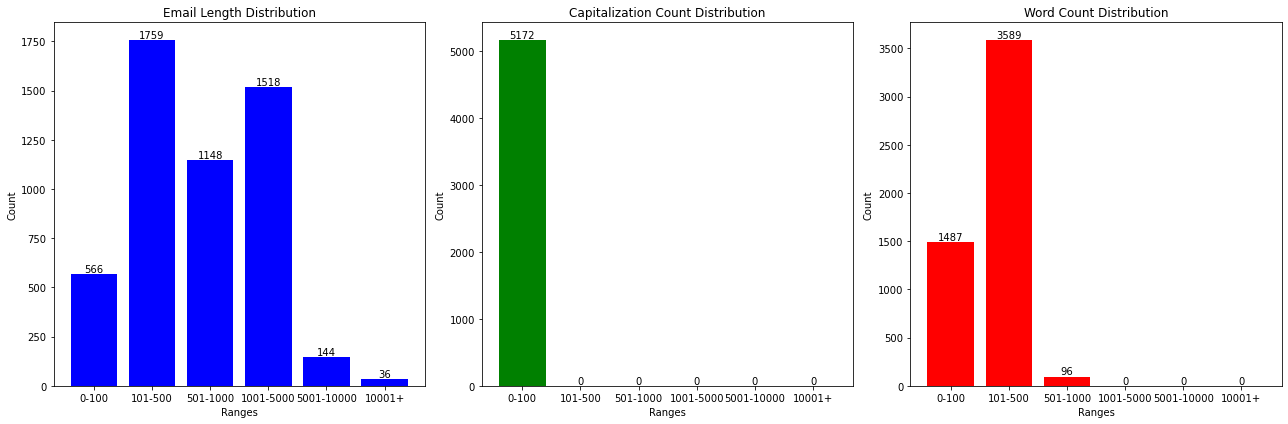

In [7]:
bins = [0, 100, 500, 1000, 5000, 10000, max(main_data['email_length'].max(), main_data['capitalization_count'].max(), main_data['word_count'].max())]
labels = ['0-100', '101-500', '501-1000', '1001-5000', '5001-10000', '10001+']

# Bin data
main_data['email_length_bin'] = pd.cut(main_data['email_length'], bins=bins, labels=labels, right=False)
main_data['capitalization_count_bin'] = pd.cut(main_data['capitalization_count'], bins=bins, labels=labels, right=False)
main_data['word_count_bin'] = pd.cut(main_data['word_count'], bins=bins, labels=labels, right=False)

# Plotting
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

# Email length distribution
email_length_counts = main_data['email_length_bin'].value_counts().sort_index()
axes[0].bar(email_length_counts.index, email_length_counts.values, color='blue')
axes[0].set_title('Email Length Distribution')
axes[0].set_xlabel('Ranges')
axes[0].set_ylabel('Count')
for i, v in enumerate(email_length_counts.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom')

# Capitalization count distribution
capitalization_count_counts = main_data['capitalization_count_bin'].value_counts().sort_index()
axes[1].bar(capitalization_count_counts.index, capitalization_count_counts.values, color='green')
axes[1].set_title('Capitalization Count Distribution')
axes[1].set_xlabel('Ranges')
axes[1].set_ylabel('Count')
for i, v in enumerate(capitalization_count_counts.values):
    axes[1].text(i, v, str(v), ha='center', va='bottom')

# Word count distribution
word_count_counts = main_data['word_count_bin'].value_counts().sort_index()
axes[2].bar(word_count_counts.index, word_count_counts.values, color='red')
axes[2].set_title('Word Count Distribution')
axes[2].set_xlabel('Ranges')
axes[2].set_ylabel('Count')
for i, v in enumerate(word_count_counts.values):
    axes[2].text(i, v, str(v), ha='center', va='bottom')

# Display the plots
plt.tight_layout()
plt.show()

In [8]:
main_data.to_excel("Updated_Mail.xlsx")

# Training the Main Data on Different Models

## 1. Naive Baise Classifiers

In [9]:
exclude_columns = ['Email No.', 'capitalization_count', 'Prediction', 'email_length_bin', 'capitalization_count_bin', 'word_count_bin']
X = main_data.drop(columns=exclude_columns)
y = main_data['Prediction']

# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create and train the Naive Bayes Classifier
model = MultinomialNB()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
performance_report = classification_report(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("\nPerformance Report:\n", performance_report)

Model Accuracy: 0.9355670103092784

Performance Report:
               precision    recall  f1-score   support

           0       0.95      0.95      0.95      1097
           1       0.89      0.89      0.89       455

    accuracy                           0.94      1552
   macro avg       0.92      0.92      0.92      1552
weighted avg       0.94      0.94      0.94      1552



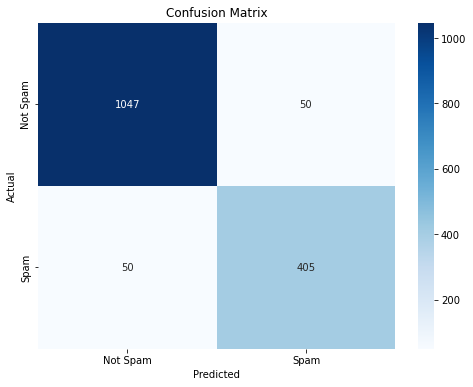

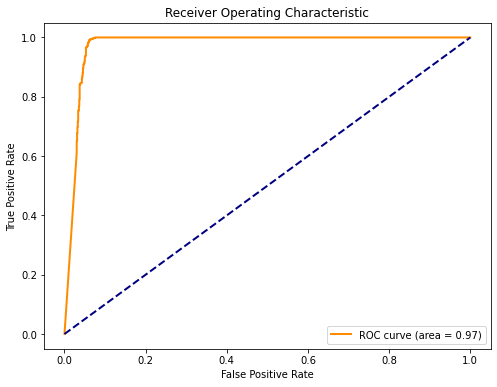

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Plotting ROC Curve for showing the Performace of the Naive Baise Machine Learning Algorithm
y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

## 2. Ranfom Forest Classifier

In [11]:
independent_columns = [col for col in main_data.columns if col not in ['Email No.', 'capitalization_count', 'Prediction', 'email_length_bin', 'capitalization_count_bin', 'word_count_bin']]

# Split the dataset into training and testing sets
X = main_data[independent_columns]
y = main_data['Prediction']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a Random Forest Classifier model
rf_classifier = RandomForestClassifier(random_state=42)

# Train the model on the training data
rf_classifier.fit(X_train, y_train)

# Save the trained model to a file using joblib
model_filename = 'spam_classification_model.joblib'
joblib.dump(rf_classifier, model_filename)

# Test the model on the test data
y_pred = rf_classifier.predict(X_test)

# Calculate the accuracy score
accuracy = accuracy_score(y_test, y_pred)

# Generate a classification report for performance evaluation
performance_report = classification_report(y_test, y_pred)

# Print the accuracy score and performance report
print(f"Accuracy Score: {accuracy}")
print("\nPerformance Report:")
print(performance_report)

Accuracy Score: 0.978743961352657

Performance Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       739
           1       0.97      0.95      0.96       296

    accuracy                           0.98      1035
   macro avg       0.98      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



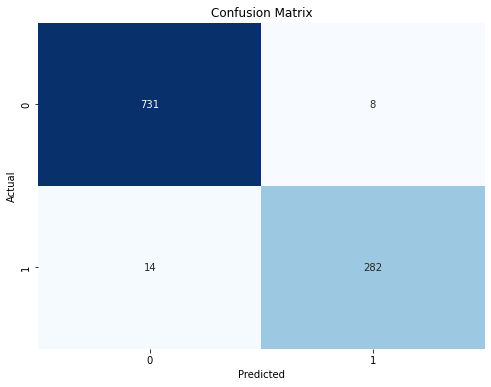

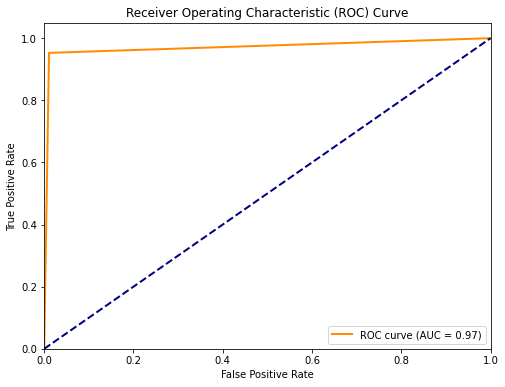

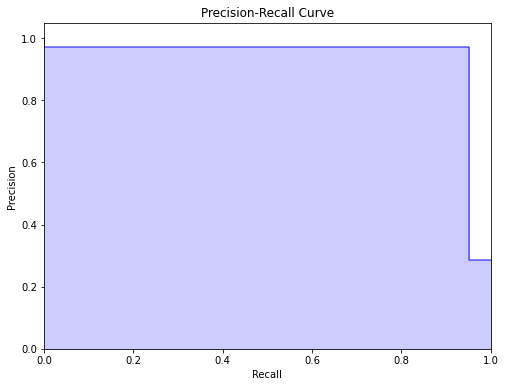

In [12]:
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# Calculate precision-recall curve
precision, recall, _ = precision_recall_curve(y_test, y_pred)

# Plot precision-recall curve
plt.figure(figsize=(8, 6))
plt.step(recall, precision, color='b', alpha=0.6, where='post')
plt.fill_between(recall, precision, step='post', alpha=0.2, color='b')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.show()

# Model Accuracy Improvement

In [13]:
desired_bins = ['101-500', '501-1000', '1001-5000']

# Filter the DataFrame based on the 'email_length_bin' column
filtered_main_data = main_data[main_data['email_length_bin'].isin(desired_bins)]

# Specify the path where you want to save the filtered data to an XLSX file
output_file_path = 'filtered_data.xlsx'

# Save the filtered data to an XLSX file
filtered_main_data.to_excel(output_file_path, index=False)

In [14]:
#Naive Baise Classifiers
exclude_columns = ['Email No.', 'capitalization_count', 'Prediction', 'email_length_bin', 'capitalization_count_bin', 'word_count_bin']
X = filtered_main_data.drop(columns=exclude_columns)
y = filtered_main_data['Prediction']

# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create and train the Naive Bayes Classifier
model = MultinomialNB()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
performance_report = classification_report(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("\nPerformance Report:\n", performance_report)

Model Accuracy: 0.9533132530120482

Performance Report:
               precision    recall  f1-score   support

           0       1.00      0.94      0.97       940
           1       0.86      1.00      0.93       388

    accuracy                           0.95      1328
   macro avg       0.93      0.97      0.95      1328
weighted avg       0.96      0.95      0.95      1328



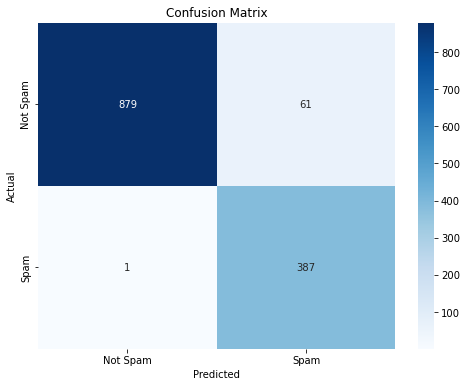

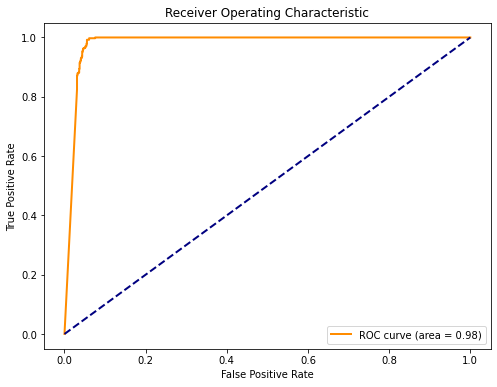

In [15]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Plotting ROC Curve
y_prob = model.predict_proba(X_test)[:, 1] # Probability estimates for the positive class
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [16]:
#Random Forest Classifier
independent_columns = [col for col in filtered_main_data.columns if col not in ['Email No.', 'capitalization_count', 'Prediction', 'email_length_bin', 'capitalization_count_bin', 'word_count_bin']]

# Split the dataset into training and testing sets
X = filtered_main_data[independent_columns]
y = filtered_main_data['Prediction']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a Random Forest Classifier model
rf_classifier = RandomForestClassifier(random_state=42)

# Train the model on the training data
rf_classifier.fit(X_train, y_train)

# Make predictions on the test data
y_pred = rf_classifier.predict(X_test)

# Calculate the accuracy score
accuracy = accuracy_score(y_test, y_pred)

# Generate a classification report for performance evaluation
performance_report = classification_report(y_test, y_pred)

# Print the accuracy score and performance report
print(f"Accuracy Score: {accuracy}")
print("\nPerformance Report:")
print(performance_report)

Accuracy Score: 0.9694915254237289

Performance Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       613
           1       0.97      0.93      0.95       272

    accuracy                           0.97       885
   macro avg       0.97      0.96      0.96       885
weighted avg       0.97      0.97      0.97       885



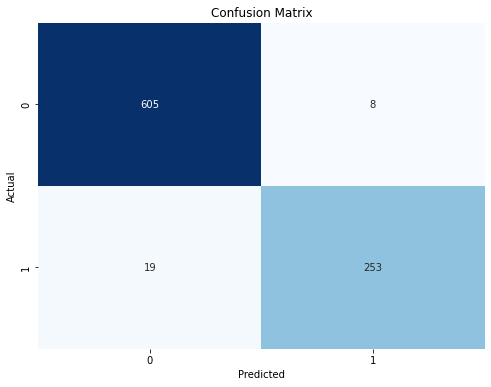

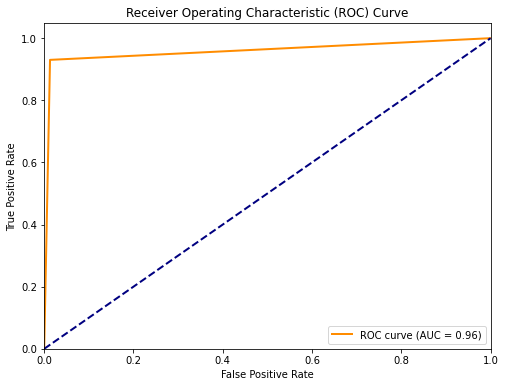

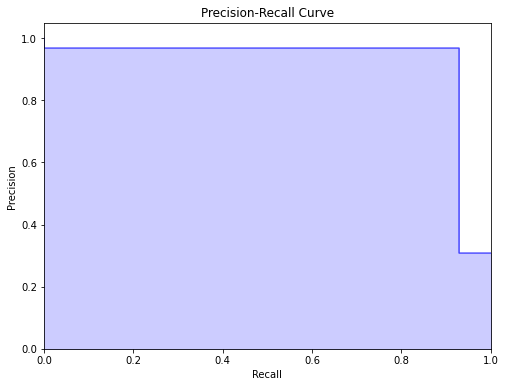

In [17]:
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# Calculate precision-recall curve
precision, recall, _ = precision_recall_curve(y_test, y_pred)

# Plot precision-recall curve
plt.figure(figsize=(8, 6))
plt.step(recall, precision, color='b', alpha=0.6, where='post')
plt.fill_between(recall, precision, step='post', alpha=0.2, color='b')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.show()

# Testing the Model Performance

In [18]:
# Function to clean and extract words from a text file
def extract_words_from_txt(filename):
    with open(filename, 'r', encoding='utf-8') as file:
        text = file.read()
        # Remove non-alphabetic characters, convert to lowercase for uniformity
        cleaned_text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
        words = cleaned_text.split()
    return words, text

# Function to compare words from the text file with column names in the Excel file
def compare_and_update_excel_v3(txt_words, full_text, input_excel, output_excel):
    df = pd.read_excel(input_excel)
    # Exclude the last six columns and 'Email No.' from the word count process
    word_columns = df.columns[1:-6]

    # Initialize the word counts to 0
    word_counts = {word: 0 for word in word_columns}

    for word in txt_words:
        if word in word_counts:
            word_counts[word] += 1

    # Calculate email length, capitalization count, and word count
    email_length = len(full_text)
    word_count = len(txt_words)

    # Add these values to the word_counts dictionary
    word_counts.update({'email_length': email_length, 
                        'word_count': word_count})

    # Append this data as a new row in the DataFrame
    new_row = pd.DataFrame([word_counts])
    df = pd.concat([df, new_row], ignore_index=True)

    # Fill any NaN values with 0
    df.fillna(0, inplace=True)

    # Save the updated DataFrame back to the Excel file
    df.to_excel(output_excel, index=False)

# Replace with the actual file paths
txt_file = 'mail.txt'
input_excel_file = 'Index.xlsx'
output_excel_file = 'updated_dummy.xlsx'

# Extract words from the text file and the full text
txt_words, full_text = extract_words_from_txt(txt_file)

# Compare and update the word counts, then save the result to the output Excel file
compare_and_update_excel_v3(txt_words, full_text, input_excel_file, output_excel_file)

In [19]:
model = joblib.load('spam_classification_model.joblib')

# Load your dataset
input_excel_file = 'updated_dummy.xlsx'  # Replace with your dataset file path
df = pd.read_excel(input_excel_file)

# Make predictions using the model
predictions = model.predict(df)

# Add predictions to the DataFrame
df['is_spam'] = predictions  # 0 for not spam, 1 for spam

# Print the predictions in a clear format
print("Email Predictions (Spam or Not):")
for index, row in df.iterrows():
    spam_status = "Spam" if row['is_spam'] == 1 else "Not Spam"
    print(f"Email {index + 1}: {spam_status}")

# Save the DataFrame with the predictions to a new Excel file
output_excel_file = 'updated_with_predictions.xlsx'
df.to_excel(output_excel_file, index=False)

Email Predictions (Spam or Not):
Email 1: Spam
